本 notebook 是 [M04.3 核方法与高斯过程](../notes/03-kernels-gaussian-processes.qmd) 的实例讲解。

1. 1. 显式特征与核矩阵
2. 2. 从零 GP 后验与 scikit-learn 对齐
3. 3. 边缘似然及梯度
4. 4. KRR 与 GP 均值的对应
5. 5. SVM 的支持向量与间隔

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.linalg import cho_factor, cho_solve
from sklearn.datasets import make_moons
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.kernel_ridge import KernelRidge
from sklearn.svm import SVC

from semiai.plotting import BLUE, ORANGE, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. 显式特征与核矩阵

对二次多项式核写出显式特征映射，并检查 Gram 矩阵半正定。

In [2]:
a = rng.normal(size=(12, 2))
phi = np.column_stack(
    [
        np.ones(len(a)),
        np.sqrt(2) * a[:, 0],
        np.sqrt(2) * a[:, 1],
        a[:, 0] ** 2,
        np.sqrt(2) * a[:, 0] * a[:, 1],
        a[:, 1] ** 2,
    ]
)
K = (1 + a @ a.T) ** 2
print("显式特征内积误差:", np.max(np.abs(K - phi @ phi.T)))
print("最小特征值:", np.linalg.eigvalsh(K).min())
assert np.allclose(K, phi @ phi.T, atol=1e-12)

显式特征内积误差: 1.4210854715202004e-14
最小特征值: -4.075781116665276e-15


读法：核技巧替换的是特征内积；有限 Gram 矩阵的微小负特征值可能来自舍入。对一批点半正定并不能证明任意自定义函数都是合法核。

## 2. 从零 GP 后验与 scikit-learn 对齐

以 Cholesky 求解实现固定超参数的零均值 GP，比较潜函数均值和标准差，不显式求逆。

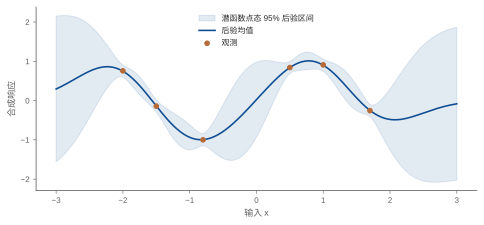

均值最大差: 5.551115123125783e-16 标准差最大差: 2.2065682614424986e-15
远离观测处的潜函数标准差: [0.94664693 0.99342376]


In [3]:
def rbf(a, b, length=0.6):
    return np.exp(-0.5 * ((a[:, None] - b[None, :]) / length) ** 2)


x = np.array([-2.0, -1.5, -0.8, 0.5, 1.0, 1.7])
y = np.sin(2 * x)
grid = np.linspace(-3, 3, 250)
noise = 0.08
factor = cho_factor(rbf(x, x) + noise**2 * np.eye(len(x)), lower=True)
mean = rbf(grid, x) @ cho_solve(factor, y)
solved = cho_solve(factor, rbf(x, grid))
std = np.sqrt(np.maximum(1 - np.sum(rbf(grid, x) * solved.T, axis=1), 0))
fig, ax = plt.subplots(figsize=(6.8, 3.2))
ax.fill_between(
    grid,
    mean - 1.96 * std,
    mean + 1.96 * std,
    color=BLUE,
    alpha=0.12,
    label="潜函数点态 95% 后验区间",
)
ax.plot(grid, mean, color=BLUE, label="后验均值")
ax.scatter(x, y, s=22, color=ORANGE, zorder=3, label="观测")
ax.set(xlabel="输入 x", ylabel="合成响应")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

model = GaussianProcessRegressor(
    kernel=RBF(0.6, length_scale_bounds="fixed"), alpha=noise**2, optimizer=None, normalize_y=False
).fit(x[:, None], y)
ref_mean, ref_std = model.predict(grid[:, None], return_std=True)
print(
    "均值最大差:", np.max(np.abs(mean - ref_mean)), "标准差最大差:", np.max(np.abs(std - ref_std))
)
print("远离观测处的潜函数标准差:", std[[0, -1]])
assert np.allclose(mean, ref_mean, atol=1e-10)
assert np.allclose(std, ref_std, atol=1e-10)

读法：alpha 表示观测噪声方差时，predict 返回的这里是潜函数标准差；预测新噪声观测还需额外加 noise²。区间条件于固定核、噪声和超参数。

## 3. 边缘似然及梯度

从数据拟合项、复杂度项和常数三部分计算对数边缘似然，用有限差分核验 sklearn 对 log length 的梯度。

In [4]:
model = GaussianProcessRegressor(kernel=RBF(0.6, (0.1, 3.0)), alpha=noise**2, optimizer=None).fit(
    x[:, None], y
)
theta = model.kernel_.theta
value, gradient = model.log_marginal_likelihood(theta, eval_gradient=True)
C = rbf(x, x) + noise**2 * np.eye(len(x))
L = np.linalg.cholesky(C)
manual = (
    -0.5 * y @ np.linalg.solve(C, y) - np.log(np.diag(L)).sum() - 0.5 * len(x) * np.log(2 * np.pi)
)
h = 1e-5
fd = (model.log_marginal_likelihood(theta + h) - model.log_marginal_likelihood(theta - h)) / (2 * h)
print("manual/sklearn LML:", manual, value, "梯度/差分:", gradient, fd)
assert np.isclose(manual, value, atol=1e-10)
assert np.allclose(gradient, fd, rtol=1e-5, atol=1e-7)

manual/sklearn LML: -6.148368069794596 -6.148368069794596 梯度/差分: [1.40709869] 1.4070986913861103


读法：对数参数化确保长度尺度为正；边缘似然可能多峰，优化后的单点超参数没有包含超参数不确定性。

## 4. KRR 与 GP 均值的对应

在同一核和同一对角正则量下比较核岭回归与 GP 后验均值，明确相同点预测不等于相同概率解释。

In [5]:
krr = KernelRidge(alpha=noise**2, kernel="rbf", gamma=1 / (2 * 0.6**2)).fit(x[:, None], y)
manual_weights = np.linalg.solve(rbf(x, x) + noise**2 * np.eye(len(x)), y)
manual_prediction = rbf(grid, x) @ manual_weights
print("KRR/GP 均值差:", np.max(np.abs(krr.predict(grid[:, None]) - mean)))
assert np.allclose(krr.predict(grid[:, None]), manual_prediction, atol=1e-10)

KRR/GP 均值差: 9.992007221626409e-16


读法：对应依赖相同零均值、同一核幅度与损失归一化；KRR 点预测本身不会自动给出 GP 的概率区间。

## 5. SVM 的支持向量与间隔

在可分的二维合成样本上检查线性硬间隔近似的几何条件，再比较 RBF 在非线性分类中的作用。

In [6]:
X = np.r_[rng.normal([-2, 0], 0.2, (25, 2)), rng.normal([2, 0], 0.2, (25, 2))]
labels = np.r_[-np.ones(25), np.ones(25)]
svm = SVC(kernel="linear", C=1e4).fit(X, labels)
margins = labels * svm.decision_function(X)
print(
    "最小函数间隔:",
    margins.min(),
    "几何间隔:",
    1 / np.linalg.norm(svm.coef_),
    "支持向量数:",
    svm.n_support_,
)
assert margins.min() > 0.99
X, labels = make_moons(n_samples=240, noise=0.12, random_state=42)
for kernel in ["linear", "rbf"]:
    fitted = SVC(kernel=kernel, C=2, gamma="scale").fit(X, labels)
    print(kernel, "训练准确率:", fitted.score(X, labels), "支持向量数:", len(fitted.support_))

最小函数间隔: 0.9999999684248341 几何间隔: 1.6204470992684472 支持向量数: [1 1]
linear 训练准确率: 0.875 支持向量数: 76
rbf 训练准确率: 0.9875 支持向量数: 34


读法：支持向量是决定边界的训练样本，函数间隔取决于规范化；训练准确率这里只展示表达能力，不是泛化评价。

## 小结

核定义相似性和函数偏好，KRR 用它做正则化拟合，SVM 用它建立间隔，GP 用它规定协方差。后验推导简单，可靠实现却依赖尺度、数值分解与清晰的噪声语义。精确对齐小系统是理解更大科学核模型的起点。